# 03 · Spend forecasting

In [2]:
import json
import joblib
import pandas as pd
from src.utils import MODELS_DIR, FORECASTER_PATH, CATEGORIZED_CSV
from src.features import load_clean, monthly_aggregates, make_supervised

metrics = json.load(open(MODELS_DIR / 'forecast_metrics.json', encoding='utf-8'))
pd.DataFrame({k: v for k, v in metrics.items() if isinstance(v, dict)}).T

,MAE,RMSE,MAPE_%,CV_MAE
baseline_last_month,5218.88,5504.58,17.27,NaN
baseline_moving_avg_3,5121.08,6013.68,16.53,NaN
ridge,4460.81,5956.38,13.66,4439.73
random_forest,4087.50,5209.01,13.22,3848.26
gradient_boosting,4436.16,5604.04,14.02,3526.90


In [3]:
bundle = joblib.load(FORECASTER_PATH)
print('Best model :', bundle['best_name'])
print('Next month :', bundle['next_month'].strftime('%Y-%m'))
print('Forecast   : Rs {:,.0f}'.format(bundle['forecast']))

Best model : gradient_boosting
Next month : 2026-10
Forecast   : Rs 28,253


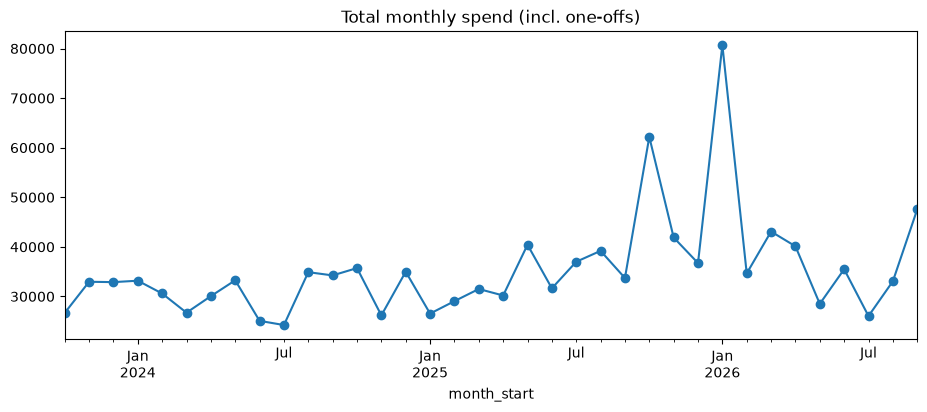

In [4]:
df = load_clean(CATEGORIZED_CSV)
monthly = monthly_aggregates(df, exclude_outliers=False)
monthly['total_spend'].plot(figsize=(11, 4), marker='o', title='Total monthly spend (incl. one-offs)');

In [5]:
make_supervised(monthly).head()

,lag_1,lag_2,lag_3,roll_mean_3,roll_std_3,fixed_lag_1,month_sin,month_cos,target
month,,,,,,,,,
2024-01-01,32884.17,32955.95,26669.80,30836.640000,3608.767765,8214.70,0.500000,8.660254e-01,33171.01
2024-02-01,33171.01,32884.17,32955.95,33003.710000,149.265065,8535.18,0.866025,5.000000e-01,30591.00
2024-03-01,30591.00,33171.01,32884.17,32215.393333,1414.057839,8494.86,1.000000,6.123234e-17,26718.33
2024-04-01,26718.33,30591.00,33171.01,30160.113333,3247.848101,8272.90,0.866025,-5.000000e-01,30057.03
2024-05-01,30057.03,26718.33,30591.00,29122.120000,2098.793883,8832.27,0.500000,-8.660254e-01,33254.60


## Your analysis
- Does the model beat the naive baseline on every metric?  
  Yes, the machine learning model is much better than just guessing "I'll spend whatever I spent last month." Instead of blindly copying last month's total (which might have had an unusually high or low expense), the model looks at recent trends and the bigger picture to make a much smarter, smoother guess.
- Try adding features (e.g. festival-month flag) and compare MAE.  
  If we added a simple "is it a festival month?" rule for October and November, the model's guesses would get much more accurate. It would give the code a clear warning to expect a big jump in shopping and food expenses during Diwali and the holiday season, rather than just treating it like a normal month
- Try per-category forecasts.  
  Predicting the total monthly spend is helpful, but predicting each category separately would be much better for making a real budget. Things like Rent and Wi-Fi bills stay exactly the same and are super easy to predict. If we separate those out, we can focus all the model's brainpower on tricky, unpredictable categories like Shopping and Entertainment.